# Chapter 5 · CNNs on images

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** [Chapter 2](02-classical-image-processing.ipynb) (convolution),
[Chapter 3](03-geometry-and-distortion.ipynb) (the sharpness measure), and neural networks from
book 26.
**You will:** train a small convolutional network to tell a photo's quality from the pixels,
beat it first with one hand-made feature, compare the two honestly, and look at what the
network's first layer learned.

Chapter 2 chose its kernels by hand. A **convolutional neural network** (CNN) learns them: the
same sliding weighted sum, stacked in layers, with the weights fitted to a task. Here the task
is useful to the reader in the challenge -- *how good is this photo?* -- because it decides
whether to trust the QR code or go straight to the text.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from torch import nn

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()
torch.manual_seed(5)
SIZE = (256, 128)                       # every photo resized to the same width x height

## The data

100 bills at five qualities: 500 photos, resized to one size so the network cannot simply read
the level off the image dimensions. The split is **by bill**: a bill is either in training or in
testing at all five qualities, never both -- otherwise the test would partly measure memory.

In [2]:
bills = qb.generate_bills(100, seed=55)
X, y, group = [], [], []
for k, b in enumerate(bills):
    clean = qb.render(b)
    for level in qb.QUALITY_LEVELS:
        photo = qb.distort(clean, level, seed=7 * k + level)
        grey = cv2.cvtColor(photo, cv2.COLOR_BGR2GRAY)
        X.append(cv2.resize(grey, SIZE, interpolation=cv2.INTER_AREA))
        y.append(level)
        group.append(k)
X, y, group = np.stack(X), np.array(y), np.array(group)
train = group < 70
print(X.shape, "| train", train.sum(), "photos of 70 bills · test", (~train).sum(), "photos of 30 bills")

(500, 128, 256) | train 350 photos of 70 bills · test 150 photos of 30 bills


## The baseline: one feature

Chapter 3's sharpness -- the variance of the Laplacian -- on its log scale, plus the image's
contrast, fed to a logistic regression. If this already separates the levels, a network has to
earn its keep.

In [3]:
def handmade(images):
    lap = np.array([cv2.Laplacian(im, cv2.CV_64F).var() for im in images])
    return np.column_stack([np.log(lap + 1), images.reshape(len(images), -1).std(axis=1)])

F = handmade(X)
baseline = LogisticRegression(max_iter=2000).fit(F[train], y[train])
base_acc = (baseline.predict(F[~train]) == y[~train]).mean()
print(f"hand-made features + logistic regression: {base_acc:.0%} of test photos at the right level")

hand-made features + logistic regression: 100% of test photos at the right level


## A small CNN

Three blocks of convolution, ReLU and pooling, then a linear layer to five scores: about
11 000 weights, tiny next to a modern vision model, so it trains on a laptop CPU in seconds.

In [4]:
class QualityNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d((4, 8)),
        )
        self.head = nn.Linear(32 * 4 * 8, 5)

    def forward(self, x):
        return self.head(self.features(x).flatten(1))

net = QualityNet()
print(sum(p.numel() for p in net.parameters()), "weights")
tx = torch.tensor(X[:, None] / 255.0, dtype=torch.float32)
ty = torch.tensor(y)
opt = torch.optim.Adam(net.parameters(), lr=3e-3)
idx = np.flatnonzero(train)
rng = np.random.default_rng(5)
history = []
for _epoch in range(25):
    net.train()
    for batch in np.array_split(rng.permutation(idx), len(idx) // 32):
        opt.zero_grad()
        loss = nn.functional.cross_entropy(net(tx[batch]), ty[batch])
        loss.backward()
        opt.step()
    net.eval()
    with torch.no_grad():
        acc = (net(tx[~train]).argmax(1) == ty[~train]).float().mean().item()
    history.append(acc)
cnn_pred = net(tx[~train]).argmax(1).numpy()
cnn_acc = (cnn_pred == y[~train]).mean()
print(f"CNN after {len(history)} epochs: {cnn_acc:.0%} of test photos at the right level")

11141 weights


CNN after 25 epochs: 99% of test photos at the right level


## Where each one errs

Accuracy hides *which* levels are confused. Neighbouring levels are close by construction;
confusing a scan with an unreadable snapshot would be a real failure.

Here the result is the lesson: the one hand-made feature already places every test photo at the
right level, and the CNN, learning from the pixels, comes to the same place. The quality levels
differ above all in blur, and chapter 3's sharpness measures exactly that. When a cheap feature
already captures the signal, the network adds cost, not accuracy -- it earns its place on tasks
where nobody can write the feature down.

wrong by more than one level: {'hand-made': '0%', 'CNN': '0%'}


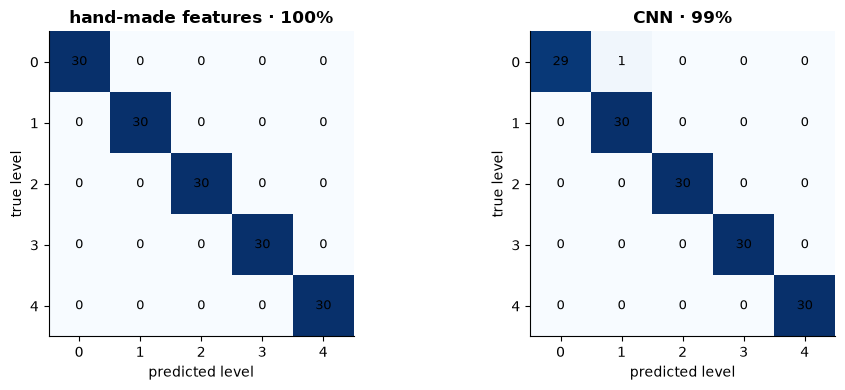

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], baseline.predict(F[~train]), f"hand-made features · {base_acc:.0%}"),
                        (axes[1], cnn_pred, f"CNN · {cnn_acc:.0%}")]:
    cm = confusion_matrix(y[~train], pred, labels=list(qb.QUALITY_LEVELS))
    ax.imshow(cm, cmap="Blues")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9)
    ax.set(xlabel="predicted level", ylabel="true level", title=title, xticks=range(5), yticks=range(5))
    ax.grid(False)
fig.tight_layout()
off_by_more = pd.Series({"hand-made": (np.abs(baseline.predict(F[~train]) - y[~train]) > 1).mean(),
                         "CNN": (np.abs(cnn_pred - y[~train]) > 1).mean()})
print("wrong by more than one level:", off_by_more.map("{:.0%}".format).to_dict())

## What the first layer learned

The eight 5 x 5 kernels of the first convolution, as images. Compare them with chapter 2's
hand-made kernels.

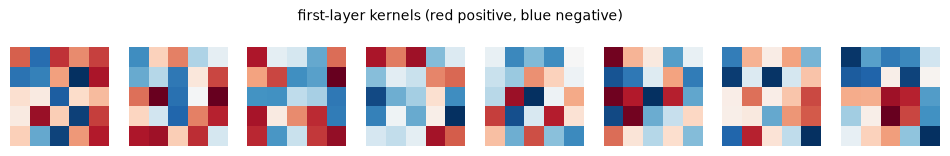

In [6]:
kernels = net.features[0].weight.detach().numpy()[:, 0]
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, k in zip(axes, kernels, strict=True):
    ax.imshow(k, cmap="RdBu_r", vmin=-abs(k).max(), vmax=abs(k).max())
    ax.axis("off")
fig.suptitle("first-layer kernels (red positive, blue negative)", fontsize=10);

## When transfer learning would pay

The usual next step for an image task is **transfer learning**: start from a network trained on
millions of photos (a ResNet, an EfficientNet) and fit only its last layers to the new task.
That pays when labelled data is scarce and the task needs rich visual features -- telling
bird species apart from a few hundred photos. It is not used here for two reasons: this shelf
runs offline, and pretrained weights are a download; and the task is narrow enough that 350
synthetic photos and 11 000 weights are already enough. Knowing when *not* to reach for the
big model is part of the method.

## What to remember

- A CNN is learned convolution. Its first layer often rediscovers edge and blur detectors.
- Try a hand-made feature first; here it was enough. Split by the unit that repeats -- the bill.
- Read the confusion matrix, not only the accuracy.

## Exercises

1. Remove the resize and give the baseline the image height as a feature. What happens, and why
   is that a leak in disguise?
2. Halve the training set. Which model degrades faster?
3. Replace `MaxPool2d` with a stride-2 convolution. Does accuracy change?

**Next:** [Chapter 6 · OCR and documents](06-ocr-and-documents.ipynb)